# Deep Learning Electricity Demand Forecasting: 1D CNN vs. LSTM vs. CNN–LSTM
## Google Colab GPU Training Pipeline & Experimental Benchmark

**Project Title:** Electricity Demand Forecasting Using Deep Learning: A Comparative Study of 1D CNN, LSTM and CNN–LSTM Models  
**Forecast Horizon:** Next 15 Minutes Ahead ($H=1$ step at 15-minute resolution)  
**Lookback Window:** Past 4 Hours ($L=16$ steps at 15-minute resolution)  
**Primary Objectives:**
1. Benchmark **1D CNN**, **LSTM**, and **CNN–LSTM** architectures.
2. Compare **Consumption-Only**, **Consumption + Retrospective Weather**, and **Consumption + Operational Weather (5-Day Latency)**.
3. Evaluate both **Individual Household / Meter Demand** and **Aggregate Cohort Demand**.

### 1. Hardware & Environment Setup

In [23]:
import os
import sys
from pathlib import Path

# Google Colab Environment Setup & Persistent Drive Mount
try:
    import google.colab
    IN_COLAB = True
    print("Running on Google Colab Environment.")
    from google.colab import drive
    drive_mount_dir = '/content/drive'
    if not os.path.exists(drive_mount_dir):
        print("Mounting Google Drive for persistent artifact storage...")
        drive.mount(drive_mount_dir)

    # Target directory on Google Drive (handles spaces in path name)
    drive_project_dir = '/content/drive/MyDrive/CNN model'
    if os.path.exists(drive_project_dir):
        os.chdir(drive_project_dir)
        print(f"Active working directory set to: {os.getcwd()}")
    else:
        print(f"Project directory {drive_project_dir} not yet mounted. Working in: {os.getcwd()}")
except ImportError:
    IN_COLAB = False
    print("Running on Local Environment.")

# Ensure project root is at the head of sys.path for robust module imports
project_root = os.getcwd()
if project_root not in sys.path:
    sys.path.insert(0, project_root)
print(f"Module import search path verified: {sys.path[0]}")

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW
from torch.optim.lr_scheduler import ReduceLROnPlateau

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
import time, copy

# GPU & CUDA Verification
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Active PyTorch Execution Device: {device}")
if torch.cuda.is_available():
    print(f"GPU Model: {torch.cuda.get_device_name(0)}")
    print(f"Total VRAM Available: {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB")
    print(f"CUDA Capability: {torch.cuda.get_device_capability(0)}")
else:
    if IN_COLAB:
        print("WARNING: GPU is not active. Please select Runtime -> Change runtime type -> T4 GPU.")
    else:
        print("CPU execution active (local development mode).")


Running on Google Colab Environment.
Active working directory set to: /content/drive/MyDrive/CNN model
Module import search path verified: /content/drive/MyDrive/CNN model
Active PyTorch Execution Device: cuda
GPU Model: Tesla T4
Total VRAM Available: 15.64 GB
CUDA Capability: (7, 5)


### 2. Deep Learning Model Architectures
We instantiate the three competitive deep learning model families under an identical regression interface.

In [24]:
class CNN1DForecaster(nn.Module):
    """1D Convolutional Neural Network with Temporal N-Gram Feature Extractors."""
    def __init__(self, in_features: int, sequence_length: int = 16, conv_channels=(64, 128, 64), dropout: float = 0.2):
        super().__init__()
        layers = []
        current_in = in_features
        for out_ch in conv_channels:
            layers.extend([
                nn.Conv1d(in_channels=current_in, out_channels=out_ch, kernel_size=3, padding=1),
                nn.BatchNorm1d(out_ch),
                nn.ReLU(),
                nn.Dropout(dropout)
            ])
            current_in = out_ch
        self.conv_stack = nn.Sequential(*layers)
        self.pool = nn.AdaptiveAvgPool1d(1)
        self.regressor = nn.Sequential(
            nn.Linear(conv_channels[-1], 32),
            nn.ReLU(),
            nn.Dropout(dropout * 0.5),
            nn.Linear(32, 1)
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x_p = x.permute(0, 2, 1)  # (batch, channels, seq)
        feat = self.conv_stack(x_p)
        pooled = self.pool(feat).squeeze(-1)
        return self.regressor(pooled)


class LSTMForecaster(nn.Module):
    """Multi-layer LSTM Recurrent Neural Network for Sequential Modeling."""
    def __init__(self, in_features: int, hidden_size: int = 64, num_layers: int = 2, dropout: float = 0.2):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size=in_features,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0.0
        )
        self.regressor = nn.Sequential(
            nn.Linear(hidden_size, 32),
            nn.ReLU(),
            nn.Dropout(dropout * 0.5),
            nn.Linear(32, 1)
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        out, _ = self.lstm(x)
        last_step = out[:, -1, :]
        return self.regressor(last_step)


class CNNLSTMForecaster(nn.Module):
    """Hybrid CNN-LSTM Architecture combining Local Feature Extraction with Sequential Modeling."""
    def __init__(self, in_features: int, cnn_channels: int = 64, lstm_hidden: int = 64, num_layers: int = 2, dropout: float = 0.2):
        super().__init__()
        self.cnn = nn.Sequential(
            nn.Conv1d(in_channels=in_features, out_channels=cnn_channels, kernel_size=3, padding=1),
            nn.BatchNorm1d(cnn_channels),
            nn.ReLU(),
            nn.Dropout(dropout)
        )
        self.lstm = nn.LSTM(
            input_size=cnn_channels,
            hidden_size=lstm_hidden,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0.0
        )
        self.regressor = nn.Sequential(
            nn.Linear(lstm_hidden, 32),
            nn.ReLU(),
            nn.Dropout(dropout * 0.5),
            nn.Linear(32, 1)
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x_conv = self.cnn(x.permute(0, 2, 1))
        x_lstm = x_conv.permute(0, 2, 1)
        out, _ = self.lstm(x_lstm)
        last_step = out[:, -1, :]
        return self.regressor(last_step)

### 3. Data Pipeline & Contiguous Sequence Slicing

In [25]:
FEATURE_CONFIGS = {
    "consumption_only": ["demand_target"],
    "consumption_weather_retro": [
        "demand_target", "retro_temperature_2m", "retro_relative_humidity_2m",
        "retro_dew_point_2m", "retro_surface_pressure", "retro_wind_speed_10m",
        "retro_direct_radiation", "retro_diffuse_radiation", "retro_cloud_cover", "retro_precipitation"
    ],
    "consumption_weather_operational": [
        "demand_target", "operational_temperature_2m", "operational_relative_humidity_2m",
        "operational_dew_point_2m", "operational_surface_pressure", "operational_wind_speed_10m",
        "operational_direct_radiation", "operational_diffuse_radiation", "operational_cloud_cover", "operational_precipitation"
    ]
}

def extract_contiguous_sequences(df, target_col, feature_cols, L=16, H=1):
    sub_df = df.copy()
    if "demand_target" in feature_cols:
        sub_df["demand_target"] = sub_df[target_col]

    all_cols = list(dict.fromkeys(feature_cols + [target_col]))
    valid_mask = sub_df[all_cols].notna().all(axis=1).values
    total_len = len(sub_df)
    W = L + H

    X_list, y_list, ts_list = [], [], []
    feat_vals = sub_df[feature_cols].values
    targ_vals = sub_df[target_col].values
    time_vals = sub_df["timestamp"].values

    for i in range(total_len - W + 1):
        if valid_mask[i : i + W].all():
            X_list.append(feat_vals[i : i + L])
            y_list.append(targ_vals[i + L + H - 1])
            ts_list.append(time_vals[i + L + H - 1])

    return np.array(X_list, dtype=np.float32), np.array(y_list, dtype=np.float32).reshape(-1, 1), np.array(ts_list)

class TorchTSDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.float32)
    def __len__(self):
        return len(self.X)
    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

### 4. Training Engine with Early Stopping & LR Scheduling

In [ ]:
def train_model(model, train_loader, val_loader, epochs=40, lr=1e-3, patience=8, device=device):
    model = model.to(device)
    criterion = nn.HuberLoss()
    optimizer = AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    scheduler = ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=4, min_lr=1e-6)

    best_val_loss = float("inf")
    best_weights = copy.deepcopy(model.state_dict())
    patience_cnt = 0
    history = {"train_loss": [], "val_loss": []}

    for ep in range(1, epochs + 1):
        model.train()
        train_loss = 0.0
        for bx, by in train_loader:
            bx, by = bx.to(device), by.to(device)
            optimizer.zero_grad()
            pred = model(bx)
            loss = criterion(pred, by)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            train_loss += loss.item()

        avg_train = train_loss / max(len(train_loader), 1)

        model.eval()
        val_loss = 0.0
        with torch.no_grad():
            for bx, by in val_loader:
                bx, by = bx.to(device), by.to(device)
                loss = criterion(model(bx), by)
                val_loss += loss.item()
        avg_val = val_loss / max(len(val_loader), 1)
        scheduler.step(avg_val)

        history["train_loss"].append(avg_train)
        history["val_loss"].append(avg_val)

        if avg_val < best_val_loss:
            best_val_loss = avg_val
            best_weights = copy.deepcopy(model.state_dict())
            patience_cnt = 0
        else:
            patience_cnt += 1
            if patience_cnt >= patience:
                break

    model.load_state_dict(best_weights)
    return model, history

def evaluate_predictions(y_true, y_pred, y_persistence=None, peak_quantile=0.95):
    yt = np.asarray(y_true, dtype=np.float64).flatten()
    yp = np.asarray(y_pred, dtype=np.float64).flatten()

    # 1. RMSE & MAE in physical kW
    rmse = float(np.sqrt(np.mean((yt - yp) ** 2)))
    mae = float(np.mean(np.abs(yt - yp)))

    # 2. WAPE (%)
    sum_yt = np.sum(yt)
    wape = float((np.sum(np.abs(yt - yp)) / sum_yt) * 100.0) if sum_yt > 1e-6 else np.nan

    # 3. MAPE (%) with zero-load guard (<0.01 kW)
    non_zero = yt >= 0.01
    mape = float(np.mean(np.abs((yt[non_zero] - yp[non_zero]) / yt[non_zero])) * 100.0) if non_zero.sum() > 0 else np.nan

    # 4. R2 score (variance explained relative to sample mean)
    ss_res = np.sum((yt - yp) ** 2)
    ss_tot = np.sum((yt - np.mean(yt)) ** 2)
    r2 = float(1.0 - (ss_res / (ss_tot + 1e-8)))

    # 5. nRMSE (%)
    nrmse = float((rmse / (np.mean(yt) + 1e-8)) * 100.0)

    # 6. Persistence Skill Score
    ss_pers = None
    if y_persistence is not None:
        ypers = np.asarray(y_persistence, dtype=np.float64).flatten()
        rmse_pers = float(np.sqrt(np.mean((yt - ypers) ** 2)))
        if rmse_pers > 1e-8:
            ss_pers = float(1.0 - ((rmse ** 2) / (rmse_pers ** 2)))

    # 7. Peak MAE (top 5% load)
    peak_thresh = np.quantile(yt, peak_quantile)
    peak_mask = yt >= peak_thresh
    peak_mae = float(np.mean(np.abs(yt[peak_mask] - yp[peak_mask]))) if peak_mask.sum() > 0 else np.nan

    return {
        "RMSE": round(rmse, 4),
        "MAE": round(mae, 4),
        "WAPE (%)": round(wape, 2) if not np.isnan(wape) else None,
        "MAPE (%)": round(mape, 2) if not np.isnan(mape) else None,
        "R2": round(r2, 4),
        "nRMSE (%)": round(nrmse, 2),
        "SS_pers": round(ss_pers, 4) if ss_pers is not None else None,
        "Peak_MAE": round(peak_mae, 4) if not np.isnan(peak_mae) else None
    }


### 5. Automated Master Benchmark Execution (36 Experiments)
We execute the approved 36-experiment matrix across:
- **Hierarchies:** Aggregate Cohorts (Mathura, Bareilly) & Individual Smart Meter Pooled Panels (Mathura, Bareilly)
- **Architectures:** 1D CNN, LSTM, CNN–LSTM
- **Feature Configurations:** Consumption-Only, Consumption + Retrospective Weather, Consumption + Operational Weather (5-Day Lag)

Checkpoints are saved to rtifacts/checkpoints/, execution logs to rtifacts/metrics/training_logs/, and final summary to rtifacts/metrics/experiment_summary.csv.

In [21]:
# Phase 3.1: Pooled Individual-Meter Training Engine (Google Colab T4 GPU)
from src.train_runner import run_master_training

# Execution is restricted strictly to target_scope='individual' (18 pooled individual runs)
# All 18 completed aggregate checkpoints and logs remain locked and preserved.
results = run_master_training(
    target_scope='individual',     # Strictly individual pooled models (9 Mathura + 9 Bareilly)
    districts=['mathura', 'bareilly'],
    epochs_ind=15,                 # 15 epochs with early stopping patience 6
    batch_size_ind=256,            # Batch size 256 initially; safe for T4 VRAM
    checkpoints_dir='artifacts/checkpoints',
    metrics_dir='artifacts/metrics',
    device='cuda' if torch.cuda.is_available() else 'cpu'
)



STARTING MASTER DEEP LEARNING TRAINING MATRIX
Target Scope: individual | Device: cuda

>>> Preparing Pooled Individual Meter Data for MATHURA ...
Found 38 meters in mathura cohort.

--- Individual Pooled MATHURA | Feature Config: consumption_only ---
Pooled Census -> Train: 1075464, Val: 230441, Test: 229281
Training pooled experiment ind_mathura_1D_CNN_consumption_only ... [COMPLETION GUARD] Experiment ind_mathura_1D_CNN_consumption_only already verified complete. Loading cached record.
Done in 330.47s (Best Ep: 11) | RMSE: 0.192 kW | WAPE: 37.92% | R2: 0.6687 | SS_pers: 0.1714
Training pooled experiment ind_mathura_LSTM_consumption_only ... Done in 318.61s (Best Ep: 11) | RMSE: 0.1906 kW | WAPE: 37.22% | R2: 0.6737 | SS_pers: 0.1837
Training pooled experiment ind_mathura_CNN_LSTM_consumption_only ... Done in 359.47s (Best Ep: 13) | RMSE: 0.1901 kW | WAPE: 37.54% | R2: 0.6754 | SS_pers: 0.188

--- Individual Pooled MATHURA | Feature Config: consumption_weather_retro ---
Pooled Census

### 6. Comparative Performance Evaluation & Visualizations


MASTER EXPERIMENT BENCHMARK SUMMARY (36 DEEP LEARNING RUNS)


,Experiment_ID,Cohort_Type,District,Model,Feature_Config,In_Features,Best_Epoch,Total_Epochs,Training_Time_s,RMSE_kW,...,MAPE_pct,R2_Score,nRMSE_pct,Persistence_Skill_Score,Peak_MAE_kW,Peak_MAPE_pct,Median_RMSE_kW,IQR_RMSE_kW,Median_R2,Median_SS_pers
0,agg_bareilly_1D_CNN_consumption_only,aggregate,bareilly,1D_CNN,consumption_only,1,14,22,20.81,2.9540,...,12.36,0.7461,15.33,-0.6405,6.1084,18.66,NaN,NaN,NaN,NaN
1,agg_bareilly_1D_CNN_consumption_weather_operat...,aggregate,bareilly,1D_CNN,consumption_weather_operational,10,8,16,16.76,5.5341,...,22.45,0.1088,28.72,-4.7578,12.1151,37.14,NaN,NaN,NaN,NaN
2,agg_bareilly_1D_CNN_consumption_weather_retro,aggregate,bareilly,1D_CNN,consumption_weather_retro,10,20,28,25.88,5.1299,...,20.00,0.2342,26.62,-3.9474,11.2861,34.57,NaN,NaN,NaN,NaN
3,agg_bareilly_CNN_LSTM_consumption_only,aggregate,bareilly,CNN_LSTM,consumption_only,1,24,32,36.17,4.8971,...,16.80,0.3021,25.41,-3.5086,13.1523,40.27,NaN,NaN,NaN,NaN
4,agg_bareilly_CNN_LSTM_consumption_weather_oper...,aggregate,bareilly,CNN_LSTM,consumption_weather_operational,10,14,22,21.59,5.3707,...,19.23,0.1606,27.87,-4.4228,13.8367,42.38,NaN,NaN,NaN,NaN
5,agg_bareilly_CNN_LSTM_consumption_weather_retro,aggregate,bareilly,CNN_LSTM,consumption_weather_retro,10,14,22,22.28,5.2069,...,18.34,0.2111,27.02,-4.0970,13.6403,41.77,NaN,NaN,NaN,NaN
6,agg_bareilly_LSTM_consumption_only,aggregate,bareilly,LSTM,consumption_only,1,12,20,14.08,3.8015,...,13.77,0.5795,19.73,-1.7169,9.8623,30.15,NaN,NaN,NaN,NaN
7,agg_bareilly_LSTM_consumption_weather_operational,aggregate,bareilly,LSTM,consumption_weather_operational,10,5,13,9.40,4.0785,...,15.09,0.5159,21.17,-2.1273,10.5491,32.27,NaN,NaN,NaN,NaN
8,agg_bareilly_LSTM_consumption_weather_retro,aggregate,bareilly,LSTM,consumption_weather_retro,10,5,13,9.32,4.1482,...,15.45,0.4993,21.53,-2.2351,10.6289,32.51,NaN,NaN,NaN,NaN
9,agg_mathura_1D_CNN_consumption_only,aggregate,mathura,1D_CNN,consumption_only,1,8,16,17.42,1.5490,...,22.06,0.8054,19.95,-0.6571,1.3451,7.72,NaN,NaN,NaN,NaN


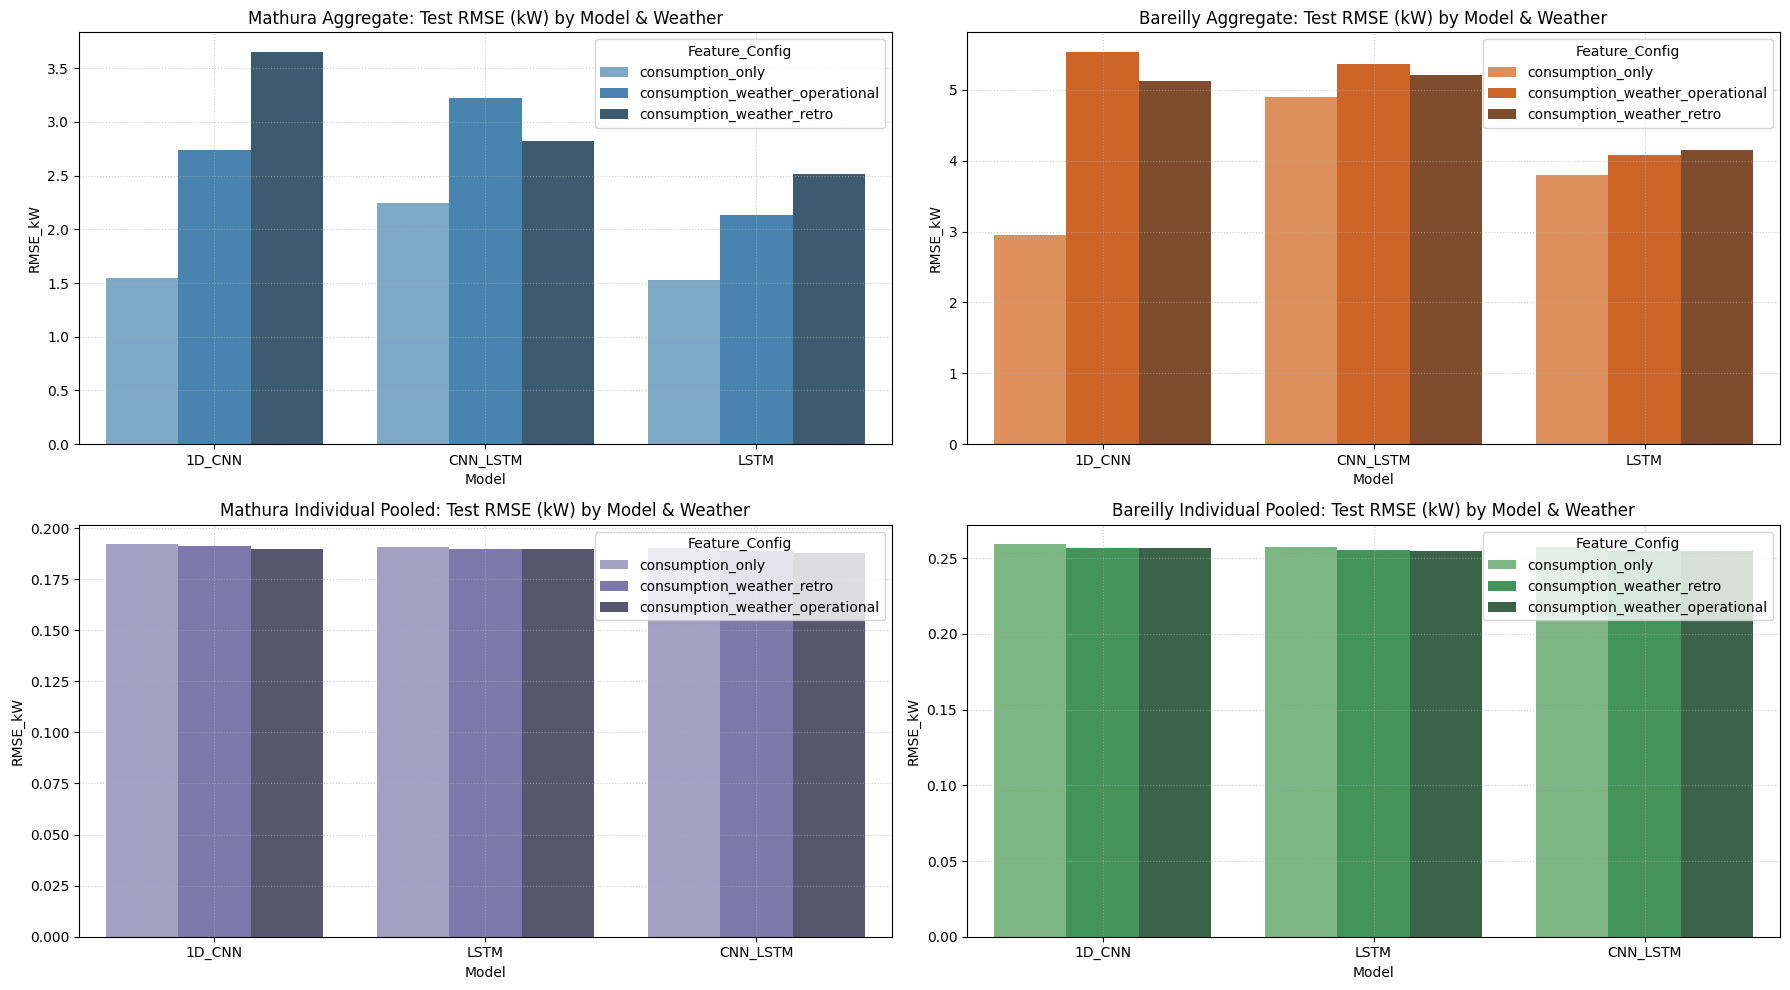

In [27]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

csv_path = Path('artifacts/metrics/experiment_summary.csv')
if csv_path.exists():
    df_results = pd.read_csv(csv_path)
    print('\n' + '='*80 + '\nMASTER EXPERIMENT BENCHMARK SUMMARY (36 DEEP LEARNING RUNS)\n' + '='*80)
    display(df_results)

    # Plot Aggregate vs Individual Comparisons
    fig, axes = plt.subplots(2, 2, figsize=(18, 10))

    # 1. Aggregate Mathura RMSE
    df_agg_m = df_results[(df_results['Cohort_Type'] == 'aggregate') & (df_results['District'] == 'mathura')]
    if not df_agg_m.empty:
        sns.barplot(data=df_agg_m, x='Model', y='RMSE_kW', hue='Feature_Config', ax=axes[0, 0], palette='Blues_d')
        axes[0, 0].set_title('Mathura Aggregate: Test RMSE (kW) by Model & Weather')
        axes[0, 0].grid(True, linestyle=':', alpha=0.6)

    # 2. Aggregate Bareilly RMSE
    df_agg_b = df_results[(df_results['Cohort_Type'] == 'aggregate') & (df_results['District'] == 'bareilly')]
    if not df_agg_b.empty:
        sns.barplot(data=df_agg_b, x='Model', y='RMSE_kW', hue='Feature_Config', ax=axes[0, 1], palette='Oranges_d')
        axes[0, 1].set_title('Bareilly Aggregate: Test RMSE (kW) by Model & Weather')
        axes[0, 1].grid(True, linestyle=':', alpha=0.6)

    # 3. Individual Mathura Pooled RMSE
    df_ind_m = df_results[(df_results['Cohort_Type'] == 'individual_pooled') & (df_results['District'] == 'mathura')]
    if not df_ind_m.empty:
        sns.barplot(data=df_ind_m, x='Model', y='RMSE_kW', hue='Feature_Config', ax=axes[1, 0], palette='Purples_d')
        axes[1, 0].set_title('Mathura Individual Pooled: Test RMSE (kW) by Model & Weather')
        axes[1, 0].grid(True, linestyle=':', alpha=0.6)

    # 4. Individual Bareilly Pooled RMSE
    df_ind_b = df_results[(df_results['Cohort_Type'] == 'individual_pooled') & (df_results['District'] == 'bareilly')]
    if not df_ind_b.empty:
        sns.barplot(data=df_ind_b, x='Model', y='RMSE_kW', hue='Feature_Config', ax=axes[1, 1], palette='Greens_d')
        axes[1, 1].set_title('Bareilly Individual Pooled: Test RMSE (kW) by Model & Weather')
        axes[1, 1].grid(True, linestyle=':', alpha=0.6)

    plt.tight_layout()
    plt.savefig('artifacts/metrics/master_experiment_comparison.png', dpi=300, bbox_inches='tight')
    plt.show()


## Section 7 - Phase 3.3: Individual Checkpoint Export & Prediction Generation

This section packages the 18 finalized individual model checkpoints and generates timestamp-level prediction artifacts on the Colab T4 GPU for local panel statistical evaluation.

- **Scientific Integrity Guard:** Sections 1-6 and aggregate checkpoints remain strictly untouched. No models are retrained.
- **Pre-Flight Verification:** Execution automatically halts if any of the 18 checkpoints are missing or if prediction generation fails.

In [1]:
# --------------------------------------------------------------------------
# 7.1 Checkpoint Pre-Flight & Packaging
# --------------------------------------------------------------------------
import os
import sys
from pathlib import Path

# Auto-mount Google Drive and auto-locate project directory if in Colab
try:
    import google.colab
    if not os.path.exists('/content/drive'):
        print('Mounting Google Drive...')
        from google.colab import drive
        drive.mount('/content/drive')
    for cand_dir in ['/content/drive/MyDrive/CNN model', '/content/CNN model', '/content']:
        if os.path.exists(cand_dir) and (Path(cand_dir) / 'artifacts' / 'checkpoints').exists():
            os.chdir(cand_dir)
            print(f'Working directory set to: {os.getcwd()}')
            break
except ImportError:
    pass

if os.getcwd() not in sys.path:
    sys.path.insert(0, os.getcwd())

# Verify that all 18 individual checkpoint files exist before packaging
expected_checkpoints = [
    f"ind_{d}_{m}_{f}.pt"
    for d in ["mathura", "bareilly"]
    for m in ["1D_CNN", "LSTM", "CNN_LSTM"]
    for f in ["consumption_only", "consumption_weather_retro", "consumption_weather_operational"]
]
ckpt_dir = Path("artifacts/checkpoints")

# Search for checkpoints
found_ckpts = list(ckpt_dir.glob("ind_*.pt")) if ckpt_dir.exists() else []
missing_ckpts = [f for f in expected_checkpoints if not (ckpt_dir / f).exists()]

print(f'Current working directory: {os.getcwd()}')
print(f'Checkpoints directory: {ckpt_dir.resolve()}')
print(f'Found {len(found_ckpts)} individual checkpoints in {ckpt_dir}.')

if missing_ckpts:
    print("=" * 80)
    print(f"PRE-FLIGHT ERROR: {len(missing_ckpts)}/18 individual checkpoints are missing!")
    for f in missing_ckpts:
        print(f"  - MISSING: {f}")
    print("\nTroubleshooting Tips:")
    print("1. If checkpoints are in your Google Drive, make sure Google Drive is mounted.")
    print("2. If this is a fresh Colab session, run Section 5 (Cell 10) to generate the checkpoints.")
    print("=" * 80)
    raise FileNotFoundError(f"Missing {len(missing_ckpts)} required individual checkpoints in {ckpt_dir.resolve()}.")
else:
    print(f"PRE-FLIGHT PASS: All 18 individual checkpoints found in {ckpt_dir}.")
    import scripts.package_colab_checkpoints as pkg
    pkg.package_individual_checkpoints(ckpt_dir_str="artifacts/checkpoints", output_zip="ind_checkpoints.zip")


Current working directory: nCheckpoints directory: artifacts\checkpoints
Found 0 individual checkpoints in artifacts\checkpoints.
PRE-FLIGHT ERROR: 18/18 individual checkpoints are missing!
  - MISSING: ind_mathura_1D_CNN_consumption_only.pt
  - MISSING: ind_mathura_1D_CNN_consumption_weather_retro.pt
  - MISSING: ind_mathura_1D_CNN_consumption_weather_operational.pt
  - MISSING: ind_mathura_LSTM_consumption_only.pt
  - MISSING: ind_mathura_LSTM_consumption_weather_retro.pt
  - MISSING: ind_mathura_LSTM_consumption_weather_operational.pt
  - MISSING: ind_mathura_CNN_LSTM_consumption_only.pt
  - MISSING: ind_mathura_CNN_LSTM_consumption_weather_retro.pt
  - MISSING: ind_mathura_CNN_LSTM_consumption_weather_operational.pt
  - MISSING: ind_bareilly_1D_CNN_consumption_only.pt
  - MISSING: ind_bareilly_1D_CNN_consumption_weather_retro.pt
  - MISSING: ind_bareilly_1D_CNN_consumption_weather_operational.pt
  - MISSING: ind_bareilly_LSTM_consumption_only.pt
  - MISSING: ind_bareilly_LSTM_consu

FileNotFoundError: Missing 18 required individual checkpoints in artifacts\checkpoints.

In [ ]:
# --------------------------------------------------------------------------
# 7.2 Individual Test Prediction Generation (Colab GPU Accelerated)
# --------------------------------------------------------------------------
from pathlib import Path
import scripts.generate_individual_predictions as gen_preds

print("Generating individual test predictions across all 84 smart meters on GPU...")
pred_df = gen_preds.generate_individual_predictions(
    checkpoints_dir="artifacts/checkpoints",
    output_dir="artifacts/metrics",
    batch_size=1024
)

parquet_path = Path("artifacts/metrics/individual_test_predictions.parquet")
if not parquet_path.exists() or pred_df is None:
    print("=" * 80)
    print("PREDICTION GENERATION ERROR: individual_test_predictions.parquet was not created!")
    print("Halting execution to prevent packaging incomplete predictions.")
    print("=" * 80)
    raise RuntimeError("Prediction generation failed.")
else:
    print("=" * 80)
    print(f"PREDICTION GENERATION SUCCESS: {parquet_path} created successfully.")
    print(f"Total prediction records: {len(pred_df):,}")
    print(f"File size: {parquet_path.stat().st_size / (1024 * 1024):.2f} MB")
    print("=" * 80)


In [ ]:
# --------------------------------------------------------------------------
# 7.3 Create Consolidated ind_transfer_package.zip
# --------------------------------------------------------------------------
import zipfile
from pathlib import Path

ckpt_zip = Path("ind_checkpoints.zip")
parquet_file = Path("artifacts/metrics/individual_test_predictions.parquet")
transfer_zip = Path("ind_transfer_package.zip")

# Pre-flight check: ensure both artifacts exist and are non-empty
if not ckpt_zip.exists() or ckpt_zip.stat().st_size == 0:
    raise FileNotFoundError("ind_checkpoints.zip is missing or empty. Cannot package transfer bundle.")
if not parquet_file.exists() or parquet_file.stat().st_size == 0:
    raise FileNotFoundError("individual_test_predictions.parquet is missing or empty. Cannot package transfer bundle.")

print(f"Creating consolidated transfer archive: {transfer_zip} ...")
with zipfile.ZipFile(transfer_zip, "w", zipfile.ZIP_DEFLATED) as zf:
    zf.write(ckpt_zip, arcname="ind_checkpoints.zip")
    zf.write(parquet_file, arcname="individual_test_predictions.parquet")
    manifest_json = Path("artifacts/checkpoints/individual_checkpoints_manifest.json")
    if manifest_json.exists():
        zf.write(manifest_json, arcname="individual_checkpoints_manifest.json")
    manifest_csv = Path("artifacts/checkpoints/individual_checkpoints_manifest.csv")
    if manifest_csv.exists():
        zf.write(manifest_csv, arcname="individual_checkpoints_manifest.csv")

print("=" * 80)
print(f"TRANSFER BUNDLE CREATED: {transfer_zip}")
print(f"Bundle size: {transfer_zip.stat().st_size / (1024 * 1024):.2f} MB")
print("Contents:")
with zipfile.ZipFile(transfer_zip, "r") as zf:
    for info in zf.infolist():
        print(f"  - {info.filename:<45} ({info.file_size / (1024 * 1024):.2f} MB uncompressed)")
print("=" * 80)


In [ ]:
# --------------------------------------------------------------------------
# 7.4 Download ind_transfer_package.zip to Local Machine
# --------------------------------------------------------------------------
from pathlib import Path

transfer_zip = Path("ind_transfer_package.zip")
if not transfer_zip.exists():
    raise FileNotFoundError("ind_transfer_package.zip not found. Run previous cells first.")

try:
    from google.colab import files
    print(f"Initiating browser download for {transfer_zip.name} ({transfer_zip.stat().st_size / (1024 * 1024):.2f} MB)...")
    files.download(str(transfer_zip))
    print("\nDownload triggered successfully.")
    print("Extract the downloaded zip into your local repository root.")
except ImportError:
    print("Notice: Not running inside Google Colab environment.")
    print(f"Please manually download or copy {transfer_zip} to your local repository.")
